In [13]:
# Run in conda ibiz environment
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import os
import pyproj
from scipy.spatial import cKDTree

# importlib seems to clutter the kernel

# CONFIGS
from preprocess_radargrams_configs import PATH_2016_AN_UTIG_ER2HI1B, PATH_2016_AN_UTIG_ER2HI2, CODE_1B, CODE_2
from preprocess_radargrams_configs import MATCHING_TOLERANCE, ROWS_CLIPPED_BLANKING, C, EPSILON_ICE
from preprocess_radargrams_configs import AMPLITUDE_VMIN, AMPLITUDE_VMAX, COLOR_MAP
from preprocess_radargrams_configs import IMAGE_TILE_WIDTH, IMAGE_TILE_HEIGHT

In [4]:
from paths import path_to_IR2HI1B, path_to_IR1HI1B
from paths import path_to_IR1HI2_ice_thickness, path_to_IR2HI2_ice_thickness

In [5]:
list_of_nc_files_HiCARS2_full_paths = sorted(
    os.path.join(path_to_IR2HI1B, f)
    for f in os.listdir(path_to_IR2HI1B)
    if f.endswith(".nc")
)

print(len(list_of_nc_files_HiCARS2_full_paths), "files found.")
print(list_of_nc_files_HiCARS2_full_paths[0])

1076 files found.
/Users/kim.bente/DATA/HiCARS/IR2HI1B/IR2HI1B_2010340_ICP3_JKB2c_F25T01b_000.nc


In [6]:
for path_to_granule in list_of_nc_files_HiCARS2_full_paths[0:]:

    ###############
    # 1. L1B data: Open nc file as xarray dataset
    radargram_ds = xr.open_dataset(path_to_granule)
    print("------------------------------")
    print("Now processing Granule ID:", radargram_ds.granule_id)
    print("L1B radargram shape (rows, columns):", radargram_ds["amplitude_high_gain"].T.shape)

    break

------------------------------
Now processing Granule ID: IR2HI1B_2010340_ICP3_JKB2c_F25T01b_000
L1B radargram shape (rows, columns): (3200, 4000)


------------------------------
Now processing Granule ID: IR2HI1B_2011004_ASB_JKB2d_GL0360a_002
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 0
L2 file path: /Users/kim.bente/DATA/HiCARS/IR2HI2_ice_thickness/IR2HI2_2011004_ASB_JKB2d_GL0360a_icethk.txt
L2 shape (rows): 26598
L2 number of columns missing LON, LAT or BOTH: 0
Matched: 4000 / 4000
Maximum residual: 4.28


/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_23865/4245923484.py:244: RuntimeWarning: invalid value encountered in cast
  bed_mask[bed_idx.astype(int), x_axis_index] = True


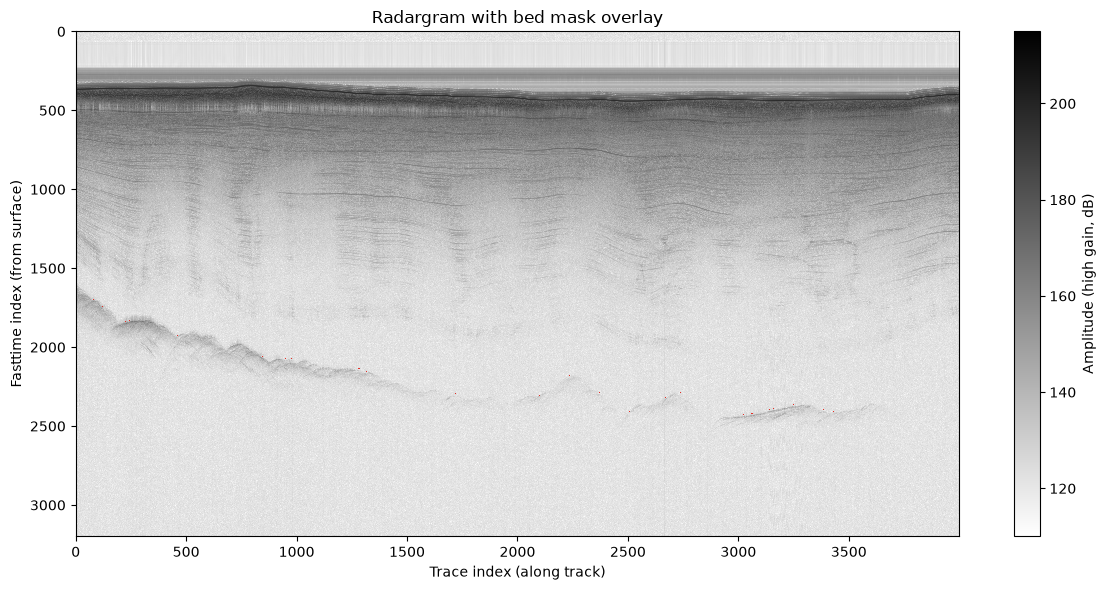

In [14]:
from matplotlib.pyplot import title

RUN_CHECKS_BOOL = True
ROWS_CLIPPED_BLANKING = ROWS_CLIPPED_BLANKING + 20

# Define before loop to avoid re-creating the transformer for each granule
HALF_TILE_WIDTH = IMAGE_TILE_WIDTH // 2
HALF_TILE_HEIGHT = IMAGE_TILE_HEIGHT // 2

lonlat_to_polarstereo = pyproj.Transformer.from_crs(crs_from = pyproj.CRS("epsg:4326"),
                                                    crs_to = pyproj.CRS("epsg:3031"),
                                                    always_xy = True) # xy order convention

# Containers
# convention: (1, 1, H, W) for PyTorch, where H is height and W is width
tiles_tensor = torch.empty((0, 1, IMAGE_TILE_HEIGHT, IMAGE_TILE_WIDTH), dtype = torch.float64)
tiles_metadata = pd.DataFrame(columns = ["survey_id", "granule_id", "x_idx", "X", "Y", "LON", "LAT", "bed_elevation", "surface_elevation", "ice_thickness", "partial_bed_reflect", "srf_reflect", "tile_along_track_span_m", "tile_vertical_span_m"])

for path_to_granule in list_of_nc_files_HiCARS2_full_paths[120:]:

    ###############
    # 1. L1B data: Open nc file as xarray dataset
    radargram_ds = xr.open_dataset(path_to_granule)
    print("------------------------------")
    print("Now processing Granule ID:", radargram_ds.granule_id)
    print("L1B radargram shape (rows, columns):", radargram_ds["amplitude_high_gain"].T.shape)

    # Sanity check
    columns_without_lonlat = (radargram_ds["lon"].isnull() | radargram_ds["lat"].isnull()).sum().item()
    print(f"L1B radargram number of columns missing LON, LAT or BOTH: {columns_without_lonlat}")

    # If there are any columns without lon/lat, crop the granule or skip this granule
    if columns_without_lonlat > 0:
        # NOTE: Often it is just the last 11/12 columns missing so we can "save" the granule
        radargram_ds_cropped = radargram_ds.isel({"time": slice(0, - columns_without_lonlat)})
        columns_without_lonlat_after_crop = (radargram_ds_cropped["lon"].isnull() | radargram_ds_cropped["lat"].isnull()).sum().item()
        if columns_without_lonlat_after_crop == 0:
            radargram_ds = radargram_ds_cropped
            print(f"INFO: Cropped {columns_without_lonlat} columns from the end of the radargram to remove missing LON, LAT values")
        else:
            print(f"WARNING: Skipping granule {radargram_ds.granule_id} due to missing lon/lat values")
            continue

    ###############
    # 2. L2 data: Open corresponding bed elevation file as pandas dataframe
    # Replace 1B with 2 in the granule ID to get the corresponding L2 granule ID
    radargram_grandule_id_L2 = radargram_ds.granule_id[:5] + "2" + radargram_ds.granule_id[7:]
    # Remove the last three characters (such as 000, 001 or 002) because L2 data filed exists per survey id, not per granule id
    # ends with _
    radargram_survey_id_L2 = radargram_grandule_id_L2[:-3]
    # print("L2 survey ID:", radargram_survey_id_L2)
    # NOTE: Hardcoded currently
    PATH_L2 = path_to_IR2HI2_ice_thickness + "/" + radargram_survey_id_L2 + "icethk.txt"
    print("L2 file path:", PATH_L2)

    # Check if the L2 file exists
    if not os.path.exists(PATH_L2):
        print(f"WARNING: L2 file {PATH_L2} does not exist")
        continue

    # Load header lines (starting with #) from the L2 file first
    with open(PATH_L2, "r") as f:
        header_lines = [line for line in f if line.startswith("#")]

    # grab last header line for the column headers
    col_names = header_lines[-1].lstrip("#").split()

    # now import the data into a pandas dataframe, skipping the header lines, but adding the column names from the last header line
    l2_df_raw = pd.read_csv(
        PATH_L2,
        sep = r"\s+", 
        # skips any line starting with '#'
        comment = "#", 
        header = None, 
        names = col_names,
    )

    print("L2 shape (rows):", l2_df_raw.shape[0])

    # SANITY CHECK: Completely remove rows with NaN values in the LON or LAT as they are not useful for our purposes
    # print(f"L2 dataframe shape before dropping rows with NaN in LON or LAT: {l2_df_raw.shape[0]}")
    # Drop them so the the lookup will just not return a match for those rows, instead of returning a match with NaN values.
    l2_df = l2_df_raw.dropna(subset = ["LON", "LAT"]) 
    # print(f"L2 dataframe shape after dropping rows with NaN in LON or LAT: {l2_df.shape[0]}")
    print(f"L2 number of columns missing LON, LAT or BOTH: {l2_df_raw.shape[0] - l2_df.shape[0]}")

    # if the L2 dataframe has no valid rows after dropping NaN values, skip this granule
    if l2_df.shape[0] == 0:
        print(f"WARNING: L2 dataframe {PATH_L2} has no valid rows after dropping NaN in LON or LAT")
        continue

    ###############
    # 3. Convert LON, LAT to X, Y coordinates in Polar Stereographic projection (EPSG:3031)
    # Pass LON and LAT columns, returns X and Y columns.
    x_array, y_array = lonlat_to_polarstereo.transform(l2_df["LON"], l2_df["LAT"])

    # Add the X and Y columns to the L2 dataframe
    l2_df["X"] = x_array
    l2_df["Y"] = y_array

    ###############
    # 4. Join L2 data onto L1B data
    PLOT_OVERLAP_BOOL = False

    if PLOT_OVERLAP_BOOL == True:

        # Overlap of L2 coordinates and radargram coordinates
        fig, ax = plt.subplots(figsize = (8, 8))

        ax.scatter(l2_df["LON"].values, l2_df["LAT"].values, 
                s = 9, alpha = 0.1, label = "L2 file", c = l2_df.index, cmap = "viridis")
        ax.scatter(radargram_ds["lon"].values, radargram_ds["lat"].values, 
                s = 1, alpha = 0.1, label = "radargram (L1B)", c = np.arange(radargram_ds.time.size), cmap = "YlOrRd_r")

        ax.scatter(l2_df["LON"].values[0], l2_df["LAT"].values[0], s = 50, color = "green", marker = "o", label = "L2 Start")
        ax.scatter(radargram_ds["lon"].values[0], radargram_ds["lat"].values[0], s = 50, color = "red", marker = "o", label = "L1B Start")

        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.legend()
        ax.set_title("Radargram vs L2 coordinates")
        plt.show()

    # KCTree worked the best here because there are some minor inconsistencies between the L1B and L2 data (e.g. float32 and float64 coordinates), so we need to find the nearest neighbor in the L2 data for each L1B trace.
    # Make dtype consistent for both: radargram coords are originally float32, but L2 coords are float64, so we need to convert them to float32 for the KDTree to work properly.
    l1b_lon = radargram_ds["lon"].values.astype(np.float32)
    l1b_lat = radargram_ds["lat"].values.astype(np.float32)

    l2_lon = l2_df["LON"].values.astype(np.float32)
    l2_lat = l2_df["LAT"].values.astype(np.float32)

    # stack
    l1b_coords = np.column_stack([l1b_lon, l1b_lat])
    l2_coords = np.column_stack([l2_lon, l2_lat])

    # build tree on l2_df (the side we're looking up / pulling matches from)
    tree = cKDTree(l2_coords)

    MATCHING_TOLERANCE = 1e-2  # degrees
    distances, indices = tree.query(l1b_coords, distance_upper_bound = MATCHING_TOLERANCE)

    # boolean indicator of whether each L1B trace has a match in the L2 data within the matching tolerance
    has_match = distances < MATCHING_TOLERANCE

    # where has_match is True, use the index from indices, otherwise use 0 to avoid indexing errors
    safe_indices = np.where(has_match, indices, 0)  # placeholder for unmatched rows

    matched_l2_subset = l2_df.iloc[safe_indices].reset_index(drop = True)

    # fill rows that weren't matched with NaN
    matched_l2_subset.loc[~ has_match] = np.nan

    # Communicate how many matches were found
    if has_match.sum() == len(l1b_coords):
        print(f"Matched: {has_match.sum()} / {len(l1b_coords)}")
    else:
        # print in red to indicate a partial match
        print(f"\033[91mMatched: {has_match.sum()} / {len(l1b_coords)}\033[0m")

    # select columns that will be added to the radargram xarray dataset
    selected_cols = ["THK", "BED_ELEVATION", "SURFACE_ELEVATION", "PARTIAL_BED_REFLECT", "SRF_REFLECT", "SRF_RNG", "X", "Y"]

    # Add the selected columns from the matched L2 subset to the radargram xarray dataset
    for col in selected_cols:
        # Add along time dimension in xarray
        radargram_ds[f"l2_{col}"] = ("time", matched_l2_subset[col].values)

    # free-up memory
    del tree

    # General consistency check:
    if RUN_CHECKS_BOOL == True:
        residual = radargram_ds["altitude"] - radargram_ds["l2_SRF_RNG"] - radargram_ds["l2_SURFACE_ELEVATION"]
        print(f"Maximum residual: {np.max(np.abs(residual)).item():.2f}")

    ###############
    # 5. Generate 2D elevation field

    # Calculate refractive index of ice
    n = np.sqrt(EPSILON_ICE)
    # Calculate speed of light in ice
    v_ice = C / n 

    ### AIR GAP HANDLING ###
    # air gap = plane altitude above surface = one-way distance from antenna to surface, in meters
    # NOTE: Alternatively use surface range (SRF_RNG) from L2 data, directly
    air_gap_m = radargram_ds.altitude.values - radargram_ds.l2_SURFACE_ELEVATION.values

    # Two-way travel time spent in air (round trip through air only, given air gap in meters (GIVEN) and speed of light in vacuum)
    air_twtt_seconds = (2 * air_gap_m) / C

    # Convert fasttime (TWTT, in microseconds) from y-axis to seconds
    fasttime_in_seconds = radargram_ds.fasttime.values * 1e-6

    ### ICE HANDLING ###
    # Subtract the air portion, leaving only the ice portion of the TWTT
    # fasttime_in_seconds is a column vector (y-axis), air_twtt_seconds is a row vector (x-axis), so we can broadcast the subtraction to get a 2D array of ice TWTT values
    # NOTE: negative values mean time still in air, so we can mask those out later if needed
    ice_twtt_seconds = fasttime_in_seconds.ravel()[:, np.newaxis] - air_twtt_seconds.ravel()[np.newaxis, :]

    # mask is true where sample is still in air (before surface return)
    in_air_mask = ice_twtt_seconds < 0

    # CONTAINER 2d array
    one_way_distance_m = np.empty_like(ice_twtt_seconds)

    ### FILL AIR CELLS given air resistance (speed of light in air) ###
    one_way_distance_m[in_air_mask] = C * fasttime_in_seconds[:, np.newaxis].repeat(ice_twtt_seconds.shape[1], axis = 1)[in_air_mask] / 2

    ### FILL ICE CELLS given ice resistance (speed of light in ice) ###
    one_way_distance_m[ ~ in_air_mask] = (air_gap_m[np.newaxis, :] + v_ice * ice_twtt_seconds / 2)[ ~ in_air_mask]

    # Get elevation above sea level (m) for column of the radargram, by subtracting the one-way distance from the plane altitude
    # This makes it Absolute
    elevation_m = radargram_ds.altitude.values[None, :] - one_way_distance_m

    ###############
    # 6. OFFSET BLANKING: Remove the first ROWS_CLIPPED_BLANKING rows of the radargram, which are blanked out due to the radar system's internal delay
    # bed idx includes the offset

    # Retrieve interpreted bed elevation values (in meters above sea level)
    # shape (4000,)
    # NOTE: some of the bed elevation values are NaN, so we need to handle that
    bed_elevation = radargram_ds.l2_BED_ELEVATION.values 

    # For each column, find the row index where elevation_m is closest to bed_elevation
    # NOTE: we need floats to allow for NaN values, so we cast to float
    bed_idx_no_offset = np.argmin(np.abs(elevation_m - bed_elevation[np.newaxis, :]), axis = 0).astype(float)

    # Propagate NaN where bed_elevation itself was NaN
    bed_idx_no_offset[np.isnan(bed_elevation)] = np.nan

    # ADD THE OFFSET for the clipped blanking rows to get the final bed index
    bed_idx = bed_idx_no_offset + ROWS_CLIPPED_BLANKING
    # print("bed_idx shape:", bed_idx.shape) 

    #### VIS 
    # 4. Create a boolean mask for the bed locations
    x_axis_index = np.arange(elevation_m.shape[1])
    # container
    bed_mask = np.zeros_like(elevation_m, dtype = bool)
    # set to 1
    # some nan values are shown as 0
    bed_mask[bed_idx.astype(int), x_axis_index] = True

    fig, ax = plt.subplots(figsize = (12, 6))

    # Transpose amplitude values to match pcolormesh's (nrows, ncols) convention
    # amplitude shape: (3200, 4000) 
    amplitude = radargram_ds["amplitude_high_gain"].values.T 

    # this x axis is easier for indexing/zooming
    fasttime_idx = np.arange(radargram_ds.fasttime.values.shape[0])                     
    trace_idx = np.arange(amplitude.shape[1])          

    mesh = ax.pcolormesh(trace_idx, fasttime_idx, amplitude, shading = "auto", cmap = COLOR_MAP, vmin = AMPLITUDE_VMIN, vmax = AMPLITUDE_VMAX)
    fig.colorbar(mesh, ax = ax, label = "Amplitude (high gain, dB)")

    # Overlay mask where we make 0's transparent (NaN) and 1's red
    mask_overlay = np.where(bed_mask, 1, np.nan) 
    ax.pcolormesh(trace_idx, fasttime_idx, mask_overlay, shading = "auto", cmap = "Reds", alpha = 1.0, vmin = 0, vmax = 1.5)

    ax.set_xlabel("Trace index (along track)")
    ax.set_ylabel("Fasttime index (from surface)")
    ax.set_title("Radargram with bed mask overlay")

    # Zoom by uncommenting this
    # ax.set_ylim(1000, 1500)

    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    break

    ###############
    # 7. CROP tiles
    # Extract and transpose high gain amplitude 2D array 
    amplitude = radargram_ds["amplitude_high_gain"].values.T 

    # Loop through x axis indices that result in a full tile
    for x_idx in range(HALF_TILE_WIDTH, amplitude.shape[1] - HALF_TILE_WIDTH, 1):
        x_center_index = x_idx

        # Calculate min and max indices
        x_min_index = x_center_index - HALF_TILE_WIDTH
        x_max_index = x_center_index + HALF_TILE_WIDTH

        # Retrieve Y CENTER INDEX from bed_idx for the current x_center_index
        y_center_index = bed_idx[x_center_index].item()

        # Skip the current iteration if y_center_index is NaN (no valid bed pick)
        if np.isnan(y_center_index):
            # print(f"Skipping x_idx {x_idx}: no valid bed pick")
            # Skips rest of loop
            continue

        # NOTE: Needs to be an integer for indexing, but bed_idx can be float due to NaN handling
        y_center_index = int(y_center_index)

        # Calculate min and max indices
        y_min_index = y_center_index - HALF_TILE_HEIGHT 
        y_max_index = y_center_index + HALF_TILE_HEIGHT

        # NOTE: Check vertical range
        if y_min_index < 0 or y_max_index >= amplitude.shape[0]:
            print(f"Skipping x_idx {x_idx}: y indices out of bounds")
            continue

        # Calculate some metrics
        # NOTE: Index by x only (along track)
        x_min_ps, x_max_ps, y_min_ps, y_max_ps = radargram_ds.l2_X[x_min_index, ].values, radargram_ds.l2_X[x_max_index, ].values, radargram_ds.l2_Y[x_min_index, ].values, radargram_ds.l2_Y[x_max_index, ].values
        along_track_span = np.sqrt((x_max_ps - x_min_ps)**2 + (y_max_ps - y_min_ps)**2)
        # along track span in meters. e.g. 336 pixels * 21 m/pixel = 7 km
        print(f"along_track_span in meters: {along_track_span:.1f}")

        # Indicate vertical span of the tile for the (x axis) center of the tile
        vertical_span = elevation_m[y_min_index, x_center_index] - elevation_m[y_max_index, x_center_index]
        print(f"vertical_span in meters: {vertical_span:.1f}")

        # Extract the tile from the amplitude array
        tile = amplitude[y_min_index : y_max_index, x_min_index : x_max_index]
        print("tile shape:", tile.shape)

        # Convert the tile to a PyTorch tensor and add a batch dimension (1, 1, H, W)
        tile_torch = torch.from_numpy(tile).unsqueeze(0).unsqueeze(0).to(torch.float64)  # (1, 1, 256, 256)
        tiles_tensor = torch.cat([tiles_tensor, tile_torch], dim = 0)
        # NOTE: could add low_amplitude tiles to a separate tensor, but for now we will just skip them

        # ADD METADATA
        tiles_metadata.loc[len(tiles_metadata)] = {
            "survey_id": radargram_survey_id_L2,
            "granule_id": radargram_ds.granule_id,
            "x_idx": x_idx,
            "X": radargram_ds.l2_X[x_center_index].item(),
            "Y": radargram_ds.l2_Y[x_center_index].item(),
            "LON": radargram_ds.lon.values[x_center_index],
            "LAT": radargram_ds.lat.values[x_center_index],
            "bed_elevation": radargram_ds.l2_BED_ELEVATION.values[x_center_index],
            "surface_elevation": radargram_ds.l2_SURFACE_ELEVATION.values[x_center_index],
            "ice_thickness": radargram_ds.l2_THK.values[x_center_index],
            "partial_bed_reflect": radargram_ds.l2_PARTIAL_BED_REFLECT.values[x_center_index],
            "srf_reflect": radargram_ds.l2_SRF_REFLECT.values[x_center_index],
            "tile_along_track_span_m": along_track_span,
            "tile_vertical_span_m": vertical_span,
        }

        break